# Módulo 1 — Punto 1.2: Calidad, Transformaciones de Intensidad y Filtrado Espacial

**Objetivo:** comprender la representación estadística de una imagen por medio de su histograma, aplicar cambios que impacten en el mismo, simular ruidos sobre la imagen y aplicar filtros.

**Cómo usar este notebook con otra foto/video:** no se toca nada acá. Se edita
`config.yaml` (ruta de la imagen o del video y la ROI) y se ejecuta todo de nuevo
(*Run All*).

Toda la lógica de cálculo está en `src/modulo1/calidad_intensidad_color.py`; este notebook
solo la llama y grafica.

## 0. Preparación del entorno

In [1]:
# --- Imports de la librería estándar ---
import sys                 # acceso a sys.path (dónde busca Python los módulos)
from pathlib import Path   # manejo de rutas independiente del sistema operativo

# --- Encontrar la raíz del repo ---
# Path.cwd() = carpeta desde donde corre el notebook (normalmente notebooks/).
# Subimos carpetas hasta encontrar config.yaml: esa es la raíz.
# Así funciona tanto si VS Code abre el notebook desde notebooks/ como desde la raíz.
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:          # llegamos a "/" sin encontrarlo
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent

# Insertamos la raíz al principio de sys.path (posición 0 = máxima prioridad).
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# --- Imports de terceros ---
import numpy as np                 # arrays (las imágenes son arrays)
import matplotlib.pyplot as plt    # gráficos
import matplotlib.patches as patches  # para dibujar el rectángulo de la ROI

# --- Imports propios ---
from src.config import cargar_config
from src.modulo1 import carga_muestreo as cm   # "cm" = alias corto
from src.modulo1 import calidad_filtrado as cf

# Leemos la configuración: un diccionario con todo lo del config.yaml
cfg = cargar_config(raiz / "config.yaml")

# Carpeta donde guardamos las figuras (se crea si no existe).
# parents=True crea carpetas intermedias; exist_ok=True no falla si ya existe.
carpeta_res = raiz / cfg["salida"]["carpeta_resultados"]
carpeta_res.mkdir(parents=True, exist_ok=True)

print("Raíz del repo:", raiz)
print("Resultados en:", carpeta_res)

Raíz del repo: c:\Users\ronal\Documents\Q2 2026\PSIB\Guia_Ojo\Guia-de-imagenes-biomedicas-G9-PSIB
Resultados en: c:\Users\ronal\Documents\Q2 2026\PSIB\Guia_Ojo\Guia-de-imagenes-biomedicas-G9-PSIB\results\modulo1


In [2]:
# Obtención de la imagen y ROI.

# Frame completo en RGB, como array (alto, ancho, 3) de uint8
img = cm.obtener_frame(cfg, raiz)

# Recorte de la ROI (copia independiente del original)
roi = cm.recortar_roi(img, cfg["roi"])

# 1.2.1 - Histograma y brillo/contraste

- `conv_grises` convierte la ROI de RGB (3 canales) a grises (1 canal) ponderando los distintos canales de acuerdo con la sensibilidad del ojo humano a estos colores.
- La funcion `histograma` recibe la ROI en escala de grises y devuelve un vector de 256 posiciones, donde la posición k contiene la cantidad de píxeles de la imagen cuya intensidad es k.

(134, 242) uint8


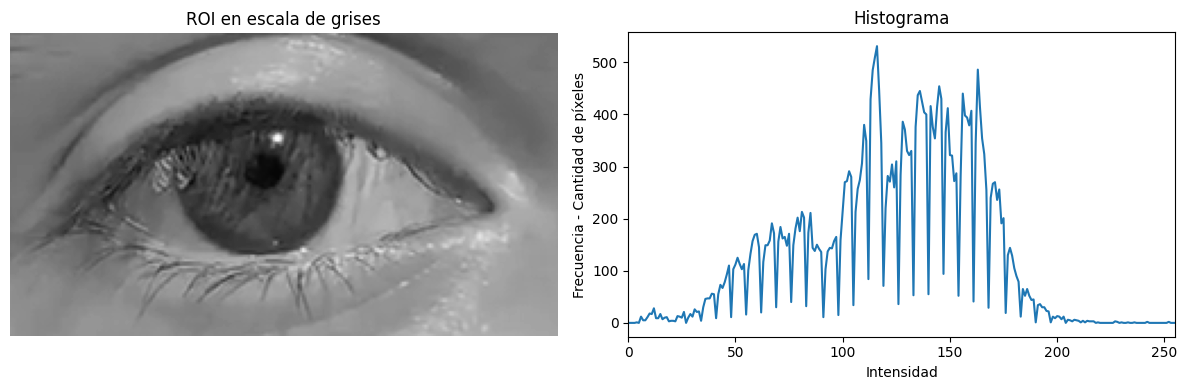

In [3]:
roi_grises = cf.conv_grises(roi) #Llamo a la función conv_grises para convertir la ROI a escala de grises
print(roi_grises.shape, roi_grises.dtype) # Chequeo que la imagen sea 2D (que ya no figuren 3 canales)y de tipo uint8

h = cf.histograma(roi_grises)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].imshow(roi_grises, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("ROI en escala de grises")
ax[0].axis("off")

ax[1].plot(h)
ax[1].set_title("Histograma")
ax[1].set_xlabel("Intensidad")
ax[1].set_ylabel("Frecuencia - Cantidad de píxeles")
ax[1].set_xlim(0, 255)

plt.tight_layout()
plt.show()

Nótese que prácticamente no hay píxeles con intesnidades por encima de 200, y que la masa principal se concentra entre 50 y 190 aproximadamente. Esto indica que la imagen es de bajo contraste.

Tiene sentido observar un pico en 120 y zonas altas entre 140 y 170, correspondientes a zonas más claras como la piel y la esclerótica. Se observa entre 50 y 100 una cierta acumulación relacionada con el iris, la pupila y las pestañas, con valores de intensidad más bajos.

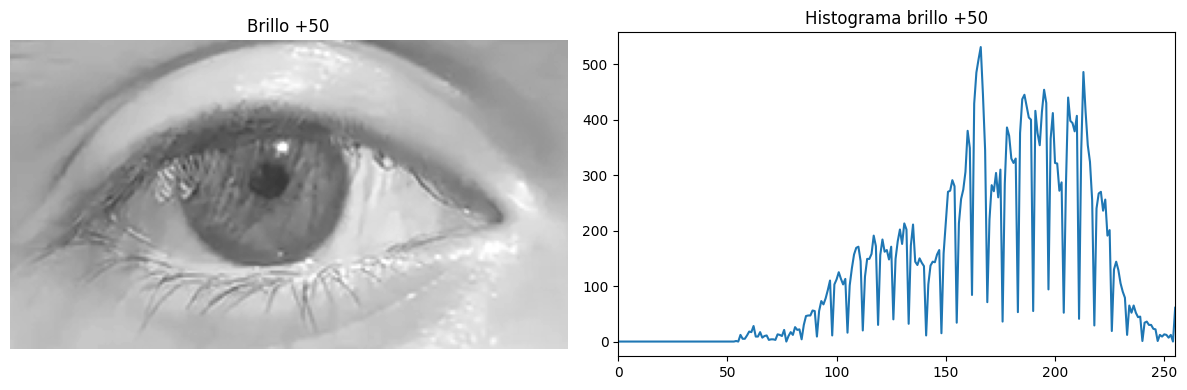

In [4]:
# Aumento el brillo en 50
roi_brillante = np.clip(roi_grises.astype(np.int16) + 50, 0, 255).astype(np.uint8)

# Calculo de nuevo el histogramas
h_brillante = cf.histograma(roi_brillante)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Imagen con brillo aumentado
ax[0].imshow(roi_brillante, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Brillo +50")
ax[0].axis("off")

# Histograma con brillo aumentado
ax[1].plot(h_brillante)
ax[1].set_title("Histograma brillo +50")
ax[1].set_xlim(0, 255)

plt.tight_layout()
plt.show()

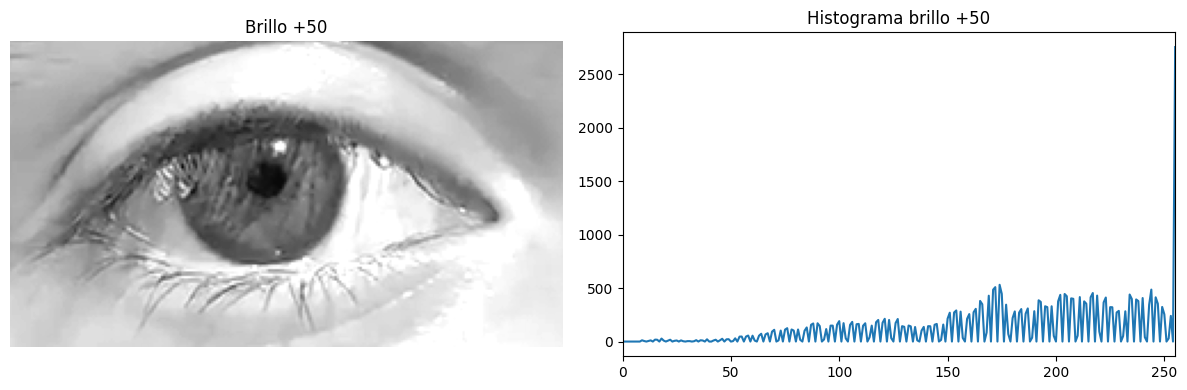

In [5]:
# Ahora en vez de sumar 50 multiplico por 1.5 (aumentando el brillo en un 50%)
roi_brillante_2 = np.clip(roi_grises.astype(np.float32) * 1.5, 0, 255).astype(np.uint8)

# Calculo de nuevo el histogramas
h_brillante_2 = cf.histograma(roi_brillante_2)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Imagen con brillo aumentado
ax[0].imshow(roi_brillante_2, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Brillo +50")
ax[0].axis("off")

# Histograma con brillo aumentado
ax[1].plot(h_brillante_2)
ax[1].set_title("Histograma brillo +50")
ax[1].set_xlim(0, 255)

plt.tight_layout()
plt.show()

**Análisis:**

- **Brillo +50:** el histograma se mueve ~50 niveles a la derecha,
  la forma no cambia. La imagen se ve más clara pero "lavada". Casi no satura porque la ROI original casi no tenía píxeles por encima de 205;
  además, el rango 0–52 queda vacío entonces ya no hay negros.
- **Contraste ×1,5:** el histograma se ensancha. Las intensidades originales mayores
  a 170 (255/1,5) se amontonan en 255 --> aparece un pico de saturación en 255. 
  Esos píxeles (piel clara, esclerótica, reflejo) pierden toda su textura: 
  ya no se pueden distinguir entre sí.
- En el segundo histograma del contraste aparecen huecos (forma de peine): los 256
  niveles de entrada se reparten en un rango 1,5 veces más ancho, así que hay
  niveles de salida que ningún píxel puede tomar (por ejemplo, 100→150 y 101→151,5≈152:
  el 151 queda vacío).
- Ninguna de las dos operaciones agrega información: solo reubica los niveles.
  El contraste mejora la separación entre pupila (oscura, queda casi igual) e
  iris, pero a costa de destruir el detalle de las zonas claras.

# 1.2.2 Escalado por rango de interés

En lugar de estirar **todo** el histograma, elegimos solo el intervalo donde
están la pupila y el iris y lo mandamos a ocupar todo el rango 0–255:

$$
s = 255\cdot\frac{r - f_1}{f_2 - f_1},\qquad
s = 0 \text{ si } r<f_1,\qquad s = 255 \text{ si } r>f_2
$$

Del histograma: la "joroba" de valores bajos (≈ 0–100) corresponde al iris, la
pupila y las pestañas. $f_1$ y $f_2$ se leen del `config.yaml`; si allí están en
`null`, se calculan por percentiles.

Antes, armamos una función reutilizable para los histogramas --> así no tenemos que estar llamando repetitivamente las mismas funciones.

In [6]:
# Módulo con brillo/contraste, escalado, ecualización, ruido, filtros y métricas.
# "cf" = alias corto (calidad_filtrado).
from src.modulo1 import calidad_filtrado as cf

# Parámetros del punto 1.2 leídos del config (sección "modulo1_2").
# p["brillo"] -> 50, p["contraste"] -> 1.5, etc.
p = cfg["modulo1_2"]

# Alias corto para la ROI en grises que calculó la celda del histograma.
g = roi_grises


def comparar(imagenes, archivo=None, titulo=None):
    '''Muestra varias imágenes en una fila y, debajo de cada una, su histograma.

    imagenes : diccionario {"título": imagen_en_grises}. Los diccionarios de
               Python mantienen el orden en que se escriben las claves, así
               que las columnas salen en ese orden.
    archivo  : nombre del .png a guardar en results/modulo1 (None = no guarda).
    titulo   : título general de la figura (opcional).
    '''
    n = len(imagenes)                                  # cantidad de columnas
    # 2 filas (imagen / histograma) x n columnas.
    # squeeze=False: aunque n sea 1, ax siempre es una grilla 2D -> ax[fila, col].
    fig, ax = plt.subplots(2, n, figsize=(4 * n, 6), squeeze=False)

    # .items() recorre el diccionario como pares (clave, valor).
    for col, (nombre, im) in enumerate(imagenes.items()):
        # --- Fila 0: la imagen ---
        # vmin/vmax fijos: negro = 0 y blanco = 255 siempre. Sin esto matplotlib
        # estira el contraste solo y NO veríamos el efecto real de cada operación.
        ax[0, col].imshow(im, cmap="gray", vmin=0, vmax=255)
        ax[0, col].set_title(nombre)
        ax[0, col].axis("off")

        # --- Fila 1: su histograma (función de la compañera) ---
        h = np.asarray(cf.histograma(im), dtype=float)   # 256 conteos
        niveles = np.arange(256)                          # eje x: 0, 1, ..., 255
        # bar dibuja una barra por nivel; width=1 -> barras pegadas.
        ax[1, col].bar(niveles, h, width=1, color="0.3")
        # Las barras de los extremos (0 y 255) en rojo: ahí se acumulan los
        # píxeles SATURADOS. Pueden ser enormes (miles de píxeles) y aplastarían
        # al resto del gráfico, así que limitamos el eje y con el máximo de los
        # niveles INTERMEDIOS (h[1:255]) + 15 %. Si el pico rojo se corta arriba,
        # su tamaño real es el porcentaje que figura en el título.
        ax[1, col].bar([0, 255], h[[0, 255]], width=3, color="tab:red")
        ax[1, col].set_ylim(0, 1.15 * max(h[1:255].max(), 1))
        ax[1, col].set_xlim(-2, 257)
        ax[1, col].set_xlabel("Intensidad")
        if col == 0:
            ax[1, col].set_ylabel("Cantidad de píxeles")

        # Porcentaje de píxeles saturados en 0 y en 255 (información perdida).
        neg, bla = cf.porcentaje_saturado(im)
        ax[1, col].set_title(f"media={im.mean():.0f}  desvío={im.std():.0f}\n"
                             f"sat. en 0: {neg:.1f} %   en 255: {bla:.1f} %",
                             fontsize=9)

    if titulo:
        fig.suptitle(titulo)
    plt.tight_layout()
    if archivo:
        fig.savefig(carpeta_res / archivo, dpi=150)
    plt.show()

Rango de interés: f1=0, f2=100  (config.yaml)


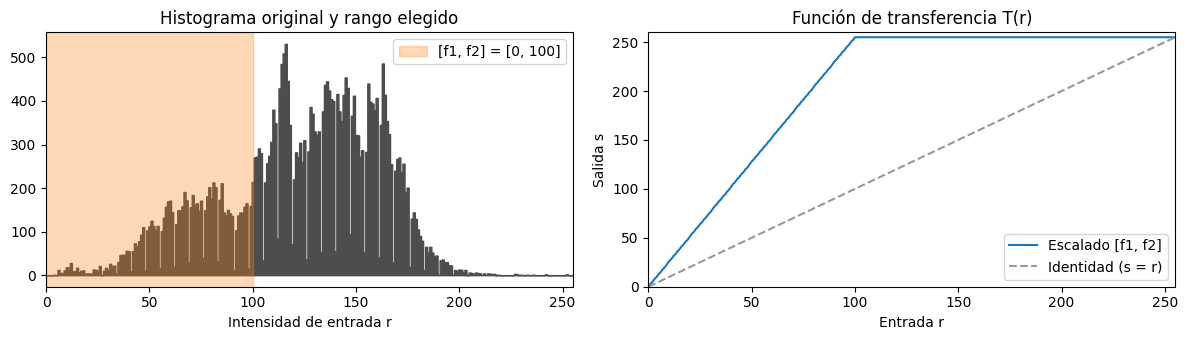

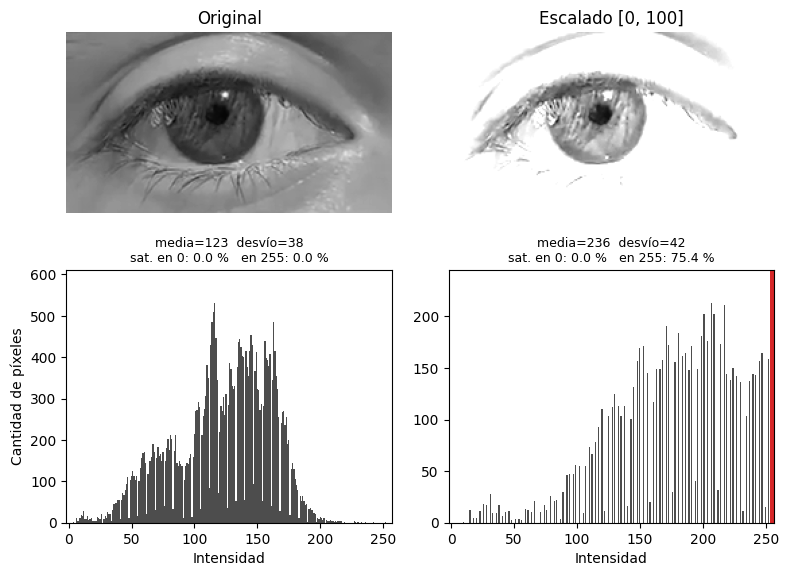

In [7]:
# --- Elegir f1 y f2 ---
if p["f1"] is None or p["f2"] is None:   # Esto elige un rango automatico, por si falla nuestra selección (para q no se rompa todo)
    # Automático: el p1 % y el p25 % más oscuros de la ROI.
    f1, f2 = cf.rango_automatico(g, p["percentil_bajo"], p["percentil_alto"])
    origen = f"automático (percentiles {p['percentil_bajo']} y {p['percentil_alto']})"
else: # Acá elegimos el rango que queremos, en este caso es el que está en el config.yaml (0-100)
    f1, f2 = p["f1"], p["f2"]
    origen = "config.yaml"
print(f"Rango de interés: f1={f1}, f2={f2}  ({origen})")

escalada = cf.escalar_rango(g, f1, f2)

# --- Figura: histograma con el rango marcado + función de transferencia T(r) ---
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))

# Izquierda: histograma original con una franja sombreada en [f1, f2].
ax[0].fill_between(np.arange(256), cf.histograma(g), color="0.3", step="mid")
ax[0].axvspan(f1, f2, color="tab:orange", alpha=0.3,       # axvspan = franja vertical
              label=f"[f1, f2] = [{f1}, {f2}]")
ax[0].set_xlim(0, 255)
ax[0].set_xlabel("Intensidad de entrada r")
ax[0].legend()
ax[0].set_title("Histograma original y rango elegido")

# Derecha: la transformación como función.
# r = todos los valores posibles 0..255, como uint8 (el tipo de una imagen).
# r_eje = lo mismo pero como enteros comunes, solo para el eje x de los gráficos.
r = np.arange(256, dtype=np.uint8)
r_eje = np.arange(256)
# Truco: aplicamos escalar_rango a un "vector-imagen" con todos los valores
# posibles -> obtenemos s = T(r) para cada r, o sea la curva de la transformación.
ax[1].plot(r_eje, cf.escalar_rango(r, f1, f2), label="Escalado [f1, f2]")
ax[1].plot(r_eje, r_eje, "--", color="0.6", label="Identidad (s = r)")
ax[1].set_xlim(0, 255); ax[1].set_ylim(0, 260)
ax[1].set_xlabel("Entrada r"); ax[1].set_ylabel("Salida s")
ax[1].legend()
ax[1].set_title("Función de transferencia T(r)")
plt.tight_layout()
fig.savefig(carpeta_res / "1_2_2_rango_transferencia.png", dpi=150)
plt.show()

comparar({"Original": g, f"Escalado [{f1}, {f2}]": escalada},
         archivo="1_2_2_escalado.png")

**Análisis:**

Se ve en la función de transferencia que la idea es saturar en 255 todos los valores por encima de f2 = 100, para hacer que las frecuencias en nuestro rango ocupen practicamente todo el resto del histograma. De esta manera, la **textura del iris y el borde pupila–iris se ven mucho más marcados**. Basicamente, le aumentamos el contraste solo a esa parte

### 1.2.3 — Ecualización de histograma: global y local (CLAHE)

**Global:** se usa como transformación la **función de distribución acumulada**
(CDF) normalizada: $s = 255\cdot\dfrac{\mathrm{CDF}(r)-\mathrm{CDF}_{min}}{1-\mathrm{CDF}_{min}}$.
Donde hay muchos píxeles la CDF sube rápido y esos niveles se separan; el
resultado tiene un histograma aproximadamente **plano**. La implementamos a mano
y verificamos contra `cv2.equalizeHist`.

**CLAHE:** ecualiza **por bloques** (grilla 8×8) y **limita** la altura de los
picos de cada histograma local para no amplificar el ruido.

Diferencia máxima con cv2.equalizeHist: 0 nivel(es) de gris


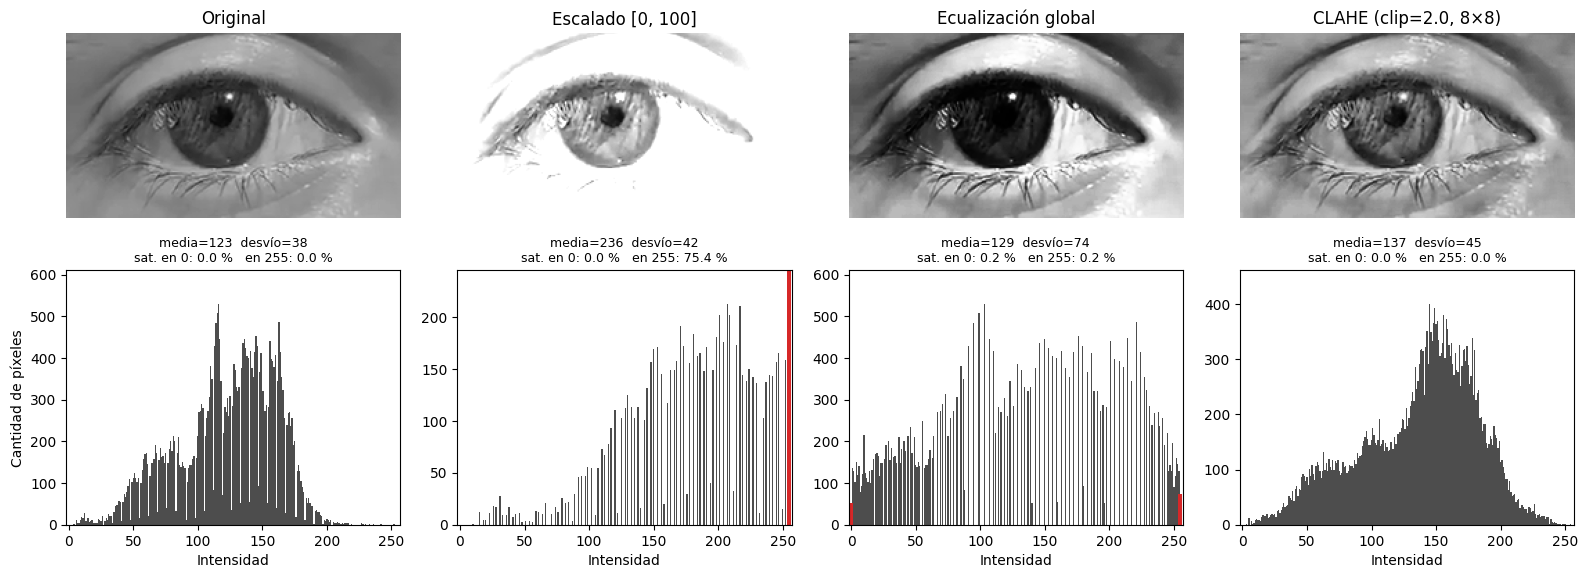

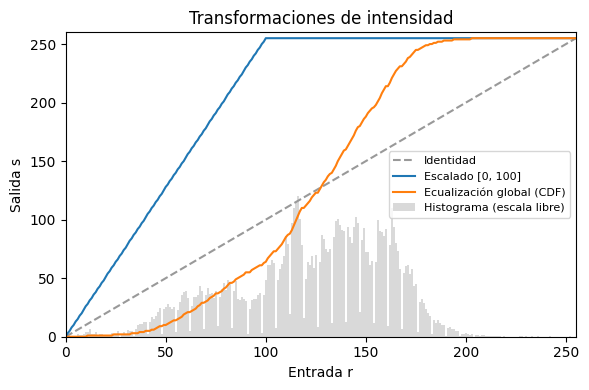

In [8]:
import cv2   # para verificar nuestra implementación contra la de OpenCV

ecualizada, lut = cf.ecualizar_global(g)       # nuestra implementación
ecualizada_cv = cv2.equalizeHist(g)            # la de OpenCV

# Diferencia máxima entre ambas (en niveles de gris). Pasamos a int para que
# la resta no "dé la vuelta" en uint8. 0 o 1 = idénticas salvo redondeo.
dif = np.abs(ecualizada.astype(int) - ecualizada_cv.astype(int)).max()
print(f"Diferencia máxima con cv2.equalizeHist: {dif} nivel(es) de gris")

clahe = cf.aplicar_clahe(g, p["clahe_clip"], p["clahe_grilla"])

comparar({"Original": g,
          f"Escalado [{f1}, {f2}]": escalada,
          "Ecualización global": ecualizada,
          f"CLAHE (clip={p['clahe_clip']}, {p['clahe_grilla']}×{p['clahe_grilla']})": clahe},
         archivo="1_2_3_ecualizacion.png")

# --- Funciones de transferencia comparadas ---
# (CLAHE no tiene UNA sola T(r): cada bloque tiene la suya, por eso no se grafica)
fig, ax = plt.subplots(figsize=(6, 4))
# Histograma original de fondo (en gris claro), re-escalado para que su pico
# llegue a 120 y entre en el mismo eje: sirve para ver DÓNDE están los píxeles.
h = np.asarray(cf.histograma(g), dtype=float)
ax.bar(r_eje, h / h.max() * 120, width=1, color="0.85", label="Histograma (escala libre)")
ax.plot(r_eje, r_eje, "--", color="0.6", label="Identidad")
ax.plot(r_eje, cf.escalar_rango(r, f1, f2), label=f"Escalado [{f1}, {f2}]")
ax.plot(r_eje, lut, label="Ecualización global (CDF)")
ax.set_xlim(0, 255); ax.set_ylim(0, 260)
ax.set_xlabel("Entrada r"); ax.set_ylabel("Salida s")
ax.legend(fontsize=8)
ax.set_title("Transformaciones de intensidad")
plt.tight_layout()
fig.savefig(carpeta_res / "1_2_3_transferencias.png", dpi=150)
plt.show()

**Análisis:**

- **Ecualización global:** el histograma queda repartido en todo 0–255 (no
  perfectamente plano, porque los niveles no se pueden "partir": todos los píxeles
  con el mismo $r$ van al mismo $s$, por eso aparecen huecos entre barras). La
  curva T(r) tiene pendiente máxima donde el histograma original tiene más
  píxeles (≈110–170: piel y esclerótica), así que el contraste "se gasta" sobre
  todo en la piel, que no nos interesa. Peor aún: para $r$ < ≈130 la curva queda
  **por debajo de la identidad** y con poca pendiente, o sea que **oscurece y
  comprime el iris y la pupila**: el borde pupila–iris pierde contraste. Artefactos: textura de la piel muy
  exagerada (aspecto granulado), ruido de compresión amplificado y bandas en
  degradés suaves.
- **CLAHE:** realza el contraste **local** — se ven mejor el borde de la pupila, la
  textura del iris y las pestañas — sin saturar regiones enteras. Artefactos:
  amplifica el ruido en zonas uniformes (piel) y puede generar halos/variaciones de
  brillo entre bloques; con `clip` más alto empeora.
- **Comparación con el escalado lineal:** el escalado es el único que pone el
  contraste **donde lo elegimos** (pupila–iris) y de forma predecible; la
  ecualización lo decide la estadística de la imagen (dominada por la piel). Para
  el pipeline de segmentación conviene escalado lineal o CLAHE moderado; la
  ecualización global no.

### 1.2.4 — Ruido

Simulamos tres ruidos típicos sobre la ROI en grises:

| Ruido | Modelo | Origen típico |
|---|---|---|
| Gaussiano | $s = r + n$, $n\sim\mathcal{N}(0,\sigma)$ | electrónica del sensor |
| Sal y pimienta | una fracción de píxeles pasa a 0 o 255 | píxeles defectuosos, errores de transmisión |
| Speckle | $s = r + r\,n$ (multiplicativo) | ecografía, OCT, iluminación coherente |

La semilla fija del config hace que el ruido "aleatorio" sea siempre el mismo.

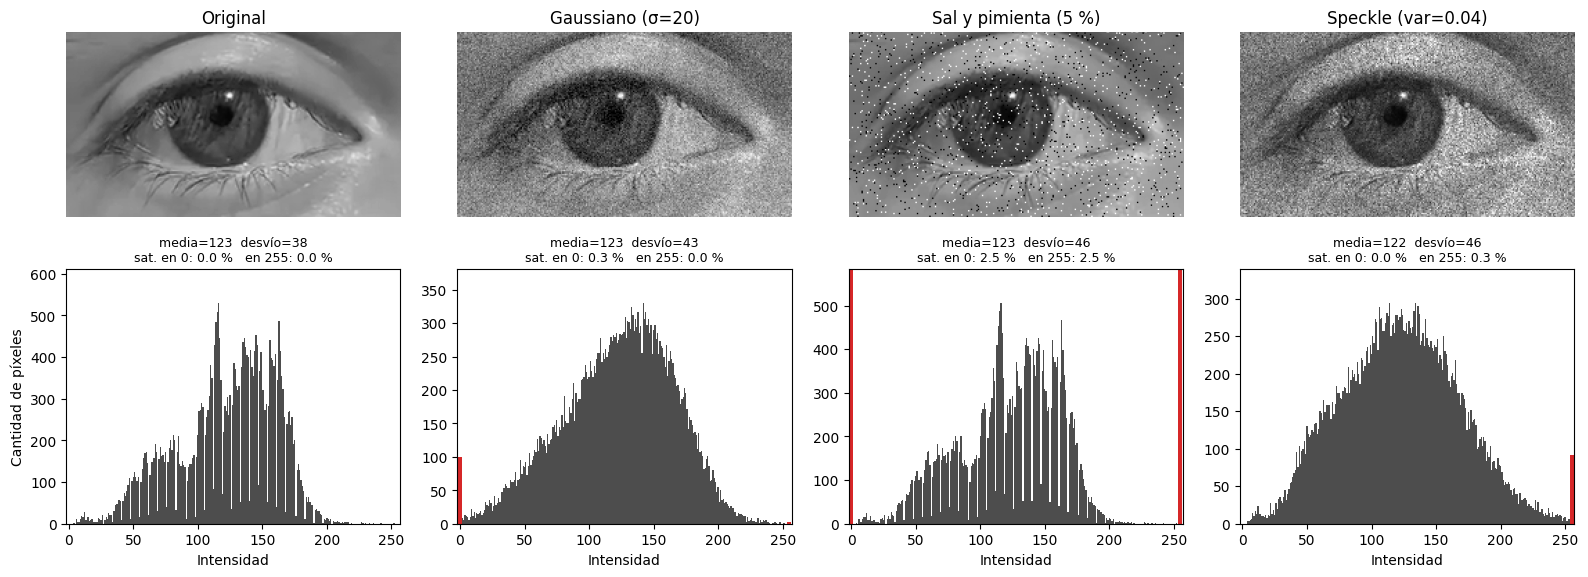

In [9]:
# Generador aleatorio con semilla fija (está en config.yaml y vale 42, aunque se puede cambiar).
rng = np.random.default_rng(p["semilla"])

# Diccionario {nombre: imagen ruidosa}. Lo reutilizamos en la celda de filtros.
ruidosas = {
    f"Gaussiano (σ={p['ruido_gauss_sigma']})":
        cf.ruido_gaussiano(g, p["ruido_gauss_sigma"], rng),
    f"Sal y pimienta ({p['ruido_sp_densidad']*100:.0f} %)":
        cf.ruido_sal_pimienta(g, p["ruido_sp_densidad"], rng),
    f"Speckle (var={p['ruido_speckle_varianza']})":
        cf.ruido_speckle(g, p["ruido_speckle_varianza"], rng),
}

# {"Original": g, **ruidosas} arma un diccionario nuevo con la original primero
# y después todas las ruidosas ("**" desarma el diccionario dentro del otro).
comparar({"Original": g, **ruidosas}, archivo="1_2_4_ruidos.png")

**Análisis de los histogramas:**

- **Gaussiano:** el histograma se "difumina" (es la convolución del original con
  una campana): los picos se ensanchan y aparecen colas que saturan levemente en 0 y 255.
- **Sal y pimienta:** el histograma de los demás píxeles queda **idéntico**, pero
  aparecen dos picos aislados exactamente en 0 y 255 (≈2,5 % cada uno).
- **Speckle:** se ensancha más en las intensidades **altas** (piel) que en las bajas
  (pupila), porque el error es proporcional al brillo: la pupila casi no se ve afectada.

### 1.2.4 — Filtros espaciales: Media, Mediana y Gaussiano

Aplicamos los tres filtros (ventana de tamaño `kernel` del config) a cada imagen
ruidosa y medimos qué tan parecido queda el resultado a la **original sin ruido**:

- **PSNR** (dB): basado en el error cuadrático medio píxel a píxel. Más alto = mejor.
- **SSIM** (−1 a 1): compara luminancia, contraste y **estructura** en ventanas
  locales; se parece más a la percepción humana. 1 = idéntica.

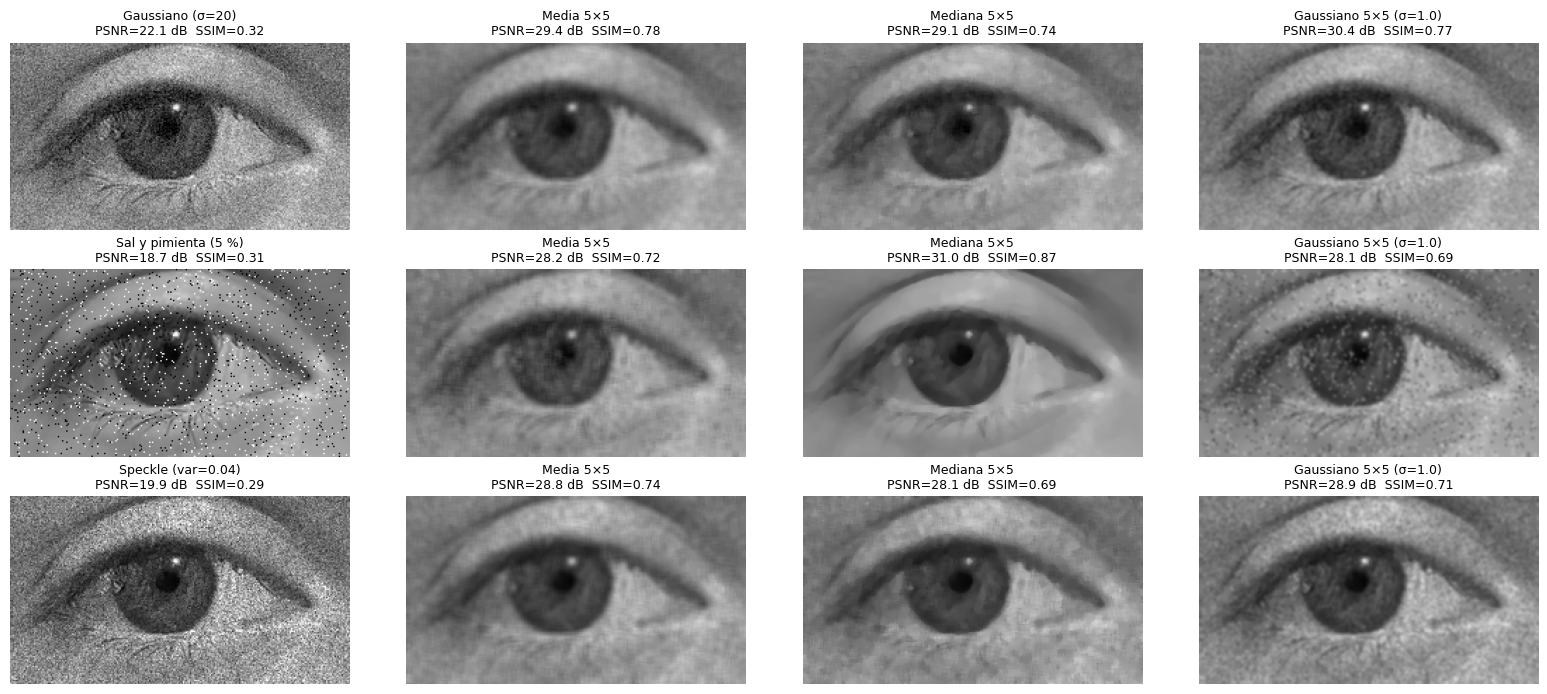

Ruido                        Filtro                     PSNR [dB]   SSIM
------------------------------------------------------------------------
Gaussiano (σ=20)             (sin filtrar)                   22.1  0.322
Gaussiano (σ=20)             Media 5×5                       29.4  0.777
Gaussiano (σ=20)             Mediana 5×5                     29.1  0.743
Gaussiano (σ=20)             Gaussiano 5×5 (σ=1.0)           30.4  0.774
Sal y pimienta (5 %)         (sin filtrar)                   18.7  0.314
Sal y pimienta (5 %)         Media 5×5                       28.2  0.724
Sal y pimienta (5 %)         Mediana 5×5                     31.0  0.869
Sal y pimienta (5 %)         Gaussiano 5×5 (σ=1.0)           28.1  0.691
Speckle (var=0.04)           (sin filtrar)                   19.9  0.288
Speckle (var=0.04)           Media 5×5                       28.8  0.737
Speckle (var=0.04)           Mediana 5×5                     28.1  0.695
Speckle (var=0.04)           Gaussiano 5×5 (σ=1.0) 

In [10]:
k = p["kernel"]

# Los tres filtros, guardados como funciones en un diccionario.
# "lambda im: ..." define una función chiquita sin nombre: recibe una imagen y
# devuelve la filtrada. Así podemos recorrerlos en un for como si fueran datos.
filtros = {
    f"Media {k}×{k}": lambda im: cf.filtro_media(im, k),
    f"Mediana {k}×{k}": lambda im: cf.filtro_mediana(im, k),
    f"Gaussiano {k}×{k} (σ={p['gauss_sigma']})": lambda im: cf.filtro_gaussiano(im, k, p["gauss_sigma"]),
}

# Grilla: una fila por tipo de ruido, columnas = ruidosa + un filtro por columna.
fig, ax = plt.subplots(len(ruidosas), len(filtros) + 1, figsize=(16, 7))
tabla = []   # acá juntamos los números para imprimir una tabla al final

for fila, (nombre_ruido, ruidosa) in enumerate(ruidosas.items()):
    # Columna 0: la imagen ruidosa, con sus métricas contra la original.
    ax[fila, 0].imshow(ruidosa, cmap="gray", vmin=0, vmax=255)
    ax[fila, 0].set_title(f"{nombre_ruido}\nPSNR={cf.psnr(g, ruidosa):.1f} dB  "
                          f"SSIM={cf.ssim(g, ruidosa):.2f}", fontsize=9)
    tabla.append((nombre_ruido, "(sin filtrar)", cf.psnr(g, ruidosa), cf.ssim(g, ruidosa)))

    # Columnas 1..3: cada filtro aplicado a esa ruidosa.
    for col, (nombre_filtro, filtrar) in enumerate(filtros.items(), start=1):
        filtrada = filtrar(ruidosa)
        v_psnr, v_ssim = cf.psnr(g, filtrada), cf.ssim(g, filtrada)
        tabla.append((nombre_ruido, nombre_filtro, v_psnr, v_ssim))
        ax[fila, col].imshow(filtrada, cmap="gray", vmin=0, vmax=255)
        ax[fila, col].set_title(f"{nombre_filtro}\nPSNR={v_psnr:.1f} dB  SSIM={v_ssim:.2f}",
                                fontsize=9)

for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
fig.savefig(carpeta_res / "1_2_4_filtros.png", dpi=150)
plt.show()

# --- Tabla de métricas ---
# f"{texto:30s}" = rellena con espacios hasta 30 caracteres (columnas alineadas).
print(f"{'Ruido':28s} {'Filtro':26s} {'PSNR [dB]':>9s} {'SSIM':>6s}")
print("-" * 72)
for ruido, filtro, v_psnr, v_ssim in tabla:
    print(f"{ruido:28s} {filtro:26s} {v_psnr:9.1f} {v_ssim:6.3f}")

**Análisis (ver la tabla de PSNR/SSIM):**

- **Gaussiano:** el filtro gaussiano es el mejor (≈22 → 30 dB, SSIM 0,34 → 0,77),
  seguido de la media: promediar reduce el ruido aditivo independiente. La mediana
  también mejora pero un poco menos. Todos desenfocan algo el borde pupilar.
- **Sal y pimienta:** la **mediana** es claramente la mejor (≈19 → 30 dB,
  SSIM 0,34 → 0,85): elimina los impulsos casi por completo. Media y gaussiano solo los
  "desparraman" en manchas grises, porque un 0 o un 255 arrastra el promedio de
  toda su ventana. Además, observar que el filtro de mediana reduce el reflejo de la pupila, ya que es un punto de intensidad muy extrema (como ruido sal y pimienta).
- **Speckle:** se comporta parecido al gaussiano (los dos son ruido "suave" en
  todos los píxeles), pero afecta sobre todo a la piel. Media y gaussiano rinden
  mejor que la mediana; entre ellos el gaussiano gana en PSNR y la media en SSIM,
  prácticamente empatados.
- PSNR y SSIM no siempre ordenan igual: el SSIM castiga más la pérdida de
  **estructura** (bordes, textura) que el PSNR.